Enter tree depth (number of levels below root, e.g., 3): 3
Enter children per node (e.g., 2 for binary tree): 2
Enter 8 leaf values separated by spaces: 2 3 5 9 0 1 7 5 

================ RESULTS ================
Best Move from Root : N1
Root Node Value     : 3
Optimal Path        : A -> N1 -> N2 -> L2
Pruned Edges        : [('N3', 'L4'), ('N4', 'N6')]


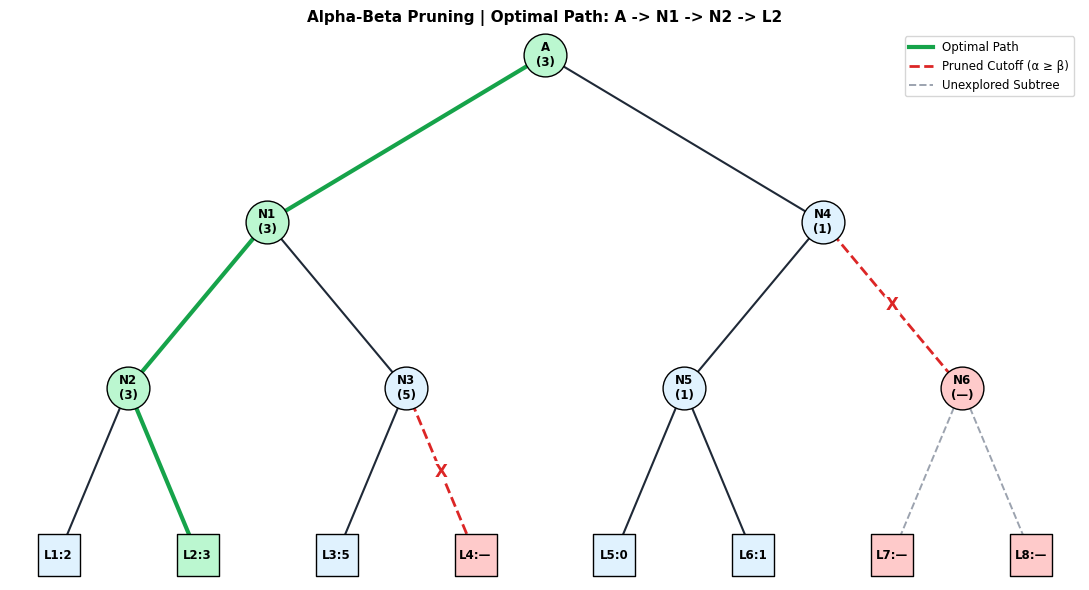

In [5]:
import math
import matplotlib.pyplot as plt


class GameTree:
    """General representation of any game tree built from compact user input."""

    def __init__(self, tree_dict, root):
        self.tree = tree_dict
        self.root = root
        self.node_values = {}
        self.pruned_edges = []

    def terminal_test(self, state):
        return isinstance(self.tree[state], (int, float))

    def utility(self, state):
        return self.tree[state]

    def actions(self, state):
        if self.terminal_test(state):
            return []
        return list(self.tree[state].keys())

    def result(self, state, action):
        return self.tree[state][action]


def build_tree_compact():
    """Builds the entire tree from 3 quick inputs: depth, branching factor, and leaf values."""
    depth = int(input("Enter tree depth (number of levels below root, e.g., 3): ").strip())
    branching = int(input("Enter children per node (e.g., 2 for binary tree): ").strip())
    expected_leaves = branching ** depth

    while True:
        raw_vals = input(f"Enter {expected_leaves} leaf values separated by spaces: ").strip().split()
        if len(raw_vals) == expected_leaves:
            try:
                leaf_values = [int(x) if float(x).is_integer() else float(x) for x in raw_vals]
                break
            except ValueError:
                print("Please enter valid numbers only.")
        else:
            print(f"Expected {expected_leaves} values, but got {len(raw_vals)}. Try again.")

    tree = {}
    leaf_idx = 0
    node_counter = 1

    def build_node(name, current_depth):
        nonlocal leaf_idx, node_counter
        if current_depth == depth:
            tree[name] = leaf_values[leaf_idx]
            leaf_idx += 1
            return

        tree[name] = {}
        for i in range(branching):
            if current_depth + 1 == depth:
                child_name = f"L{leaf_idx + 1}"
            else:
                child_name = f"N{node_counter}"
                node_counter += 1
            tree[name][f"move_{i + 1}"] = child_name
            build_node(child_name, current_depth + 1)

    build_node("A", 0)
    return GameTree(tree, "A")


def alpha_beta_search(game, state):
    """Exact implementation of ALPHA-BETA-SEARCH."""
    v, best_path = max_value(game, state, -math.inf, math.inf)
    best_action = best_path[1] if len(best_path) > 1 else None
    return best_action, v, best_path


def max_value(game, state, alpha, beta):
    """Exact implementation of MAX-VALUE(state, alpha, beta)."""
    if game.terminal_test(state):
        val = game.utility(state)
        game.node_values[state] = val
        return val, [state]

    v = -math.inf
    best_path = []
    action_list = game.actions(state)

    for idx, a in enumerate(action_list):
        child = game.result(state, a)
        child_val, child_path = min_value(game, child, alpha, beta)

        if child_val > v:
            v = child_val
            best_path = [state] + child_path

        if v >= beta:
            for rem_a in action_list[idx + 1 :]:
                pruned_child = game.result(state, rem_a)
                game.pruned_edges.append((state, pruned_child))
            game.node_values[state] = v
            return v, best_path

        alpha = max(alpha, v)

    game.node_values[state] = v
    return v, best_path


def min_value(game, state, alpha, beta):
    """Exact implementation of MIN-VALUE(state, alpha, beta)."""
    if game.terminal_test(state):
        val = game.utility(state)
        game.node_values[state] = val
        return val, [state]

    v = math.inf
    best_path = []
    action_list = game.actions(state)

    for idx, a in enumerate(action_list):
        child = game.result(state, a)
        child_val, child_path = max_value(game, child, alpha, beta)

        if child_val < v:
            v = child_val
            best_path = [state] + child_path

        if v <= alpha:
            for rem_a in action_list[idx + 1 :]:
                pruned_child = game.result(state, rem_a)
                game.pruned_edges.append((state, pruned_child))
            game.node_values[state] = v
            return v, best_path

        beta = min(beta, v)

    game.node_values[state] = v
    return v, best_path


def plot_tree_graph(game, opt_path):
    """Displays the final graphical tree showing optimal path and pruned branches."""
    positions = {}
    leaf_counter = 0

    def assign_coords(node, depth=0):
        nonlocal leaf_counter
        if game.terminal_test(node):
            positions[node] = (leaf_counter, -depth)
            leaf_counter += 1
        else:
            children = [game.result(node, a) for a in game.actions(node)]
            for c in children:
                assign_coords(c, depth + 1)
            xs = [positions[c][0] for c in children]
            positions[node] = (sum(xs) / len(xs), -depth)

    assign_coords(game.root)
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.axis("off")

    def draw_edges(node, parent_pruned=False):
        if game.terminal_test(node):
            return
        x1, y1 = positions[node]
        for a in game.actions(node):
            child = game.result(node, a)
            x2, y2 = positions[child]
            is_cut = (node, child) in game.pruned_edges
            is_sub_pruned = parent_pruned or is_cut
            is_opt = (
                node in opt_path
                and child in opt_path
                and opt_path.index(child) == opt_path.index(node) + 1
            )

            if is_opt:
                ax.plot([x1, x2], [y1, y2], color="#16a34a", lw=3, zorder=1)
            elif is_cut:
                ax.plot([x1, x2], [y1, y2], color="#dc2626", lw=2, ls="--", zorder=1)
                ax.text(
                    (x1 + x2) / 2,
                    (y1 + y2) / 2,
                    "X",
                    color="#dc2626",
                    fontsize=12,
                    fontweight="bold",
                    ha="center",
                    va="center",
                    bbox=dict(boxstyle="round,pad=0.1", facecolor="white", edgecolor="none"),
                )
            elif is_sub_pruned:
                ax.plot([x1, x2], [y1, y2], color="#9ca3af", lw=1.4, ls="--", zorder=1)
            else:
                ax.plot([x1, x2], [y1, y2], color="#1f2937", lw=1.5, zorder=1)

            draw_edges(child, is_sub_pruned)

    draw_edges(game.root)

    for node, (x, y) in positions.items():
        val = game.node_values.get(node, "—")
        label = f"{node}\n({val})" if not game.terminal_test(node) else f"{node}:{val}"
        color = (
            "#bbf7d0"
            if node in opt_path
            else ("#fecaca" if node not in game.node_values else "#e0f2fe")
        )
        ax.scatter(
            x,
            y,
            s=950,
            color=color,
            edgecolors="black",
            zorder=3,
            marker="s" if game.terminal_test(node) else "o",
        )
        ax.text(
            x,
            y,
            label,
            ha="center",
            va="center",
            fontsize=8.5,
            fontweight="bold",
            zorder=4,
        )

    ax.plot([], [], color="#16a34a", lw=3, label="Optimal Path")
    ax.plot([], [], color="#dc2626", lw=2, ls="--", label="Pruned Cutoff (α ≥ β)")
    ax.plot([], [], color="#9ca3af", lw=1.4, ls="--", label="Unexplored Subtree")
    ax.legend(loc="upper right", frameon=True, fontsize=8.5)

    plt.title(
        f"Alpha-Beta Pruning | Optimal Path: {' -> '.join(opt_path)}",
        fontsize=11,
        fontweight="bold",
    )
    plt.tight_layout()
    plt.show()


# =====================================================================
# Main Execution
# =====================================================================
if __name__ == "__main__":
    game = build_tree_compact()
    best_move, root_val, optimal_path = alpha_beta_search(game, game.root)

    print("\n================ RESULTS ================")
    print(f"Best Move from Root : {best_move}")
    print(f"Root Node Value     : {root_val}")
    print(f"Optimal Path        : {' -> '.join(optimal_path)}")
    print(f"Pruned Edges        : {game.pruned_edges}")

    plot_tree_graph(game, optimal_path)
